# Training data exploratory analysis

Analyze the cleaned IEEE-CIS data using only the first 472,432 rows in chronological order. Shared computations live in `src/eda.py`. All plots and tables are local, and no validation or test statistics are computed. Missing values and all V columns are retained.

Run all cells to regenerate `reports/eda_findings.md`, `reports/eda/`, and seven PNG figures in `reports/figures/`.

In [1]:
import os
import sys
import tempfile
from pathlib import Path

root = Path.cwd()
if not (root / "src").is_dir():
    root = root.parent
sys.path.insert(0, str(root))
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "bt4012-matplotlib"))
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import display, Image
from src.eda import run, OUTPUT

plt.rcParams.update({"font.size": 10, "axes.titlesize": 12, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.facecolor": "white"})
BLUE, RED = "#276A9A", "#BE493D"
figures = root / "reports" / "figures"
figures.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    path = figures / ("eda_" + name + ".png")
    fig.savefig(path, dpi=150, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(filename=str(path)))

train, tables, summary = run()
baseline = 100 * summary["fraud_rate"]
assert len(train) == 472_432
print("All group counts, fraud counts, and missingness totals reconcile.")

Matplotlib is building the font cache; this may take a moment.


{
  "source": "data/processed/cleaned.parquet",
  "scope": "training only; rows 0 through 472431 in chronological order",
  "train_rows": 472432,
  "columns": 436,
  "fraud_count": 16599,
  "fraud_rate": 0.03513521522674162,
  "first_transaction_dt": 86400,
  "last_transaction_dt": 12192842,
  "first_day": 1,
  "last_day": 141,
  "missing_cells_pct": 44.864694667576835,
  "columns_with_missing": 414,
  "columns_over_90pct_missing": 12,
  "table_reconciliation_passed": true,
  "validation_or_test_analyzed": false,
  "fitted_transforms_or_models": false
}
All group counts, fraud counts, and missingness totals reconcile.


## Class balance

The fraud class is a small minority. Counts below are training counts; no sampling or balancing is applied.

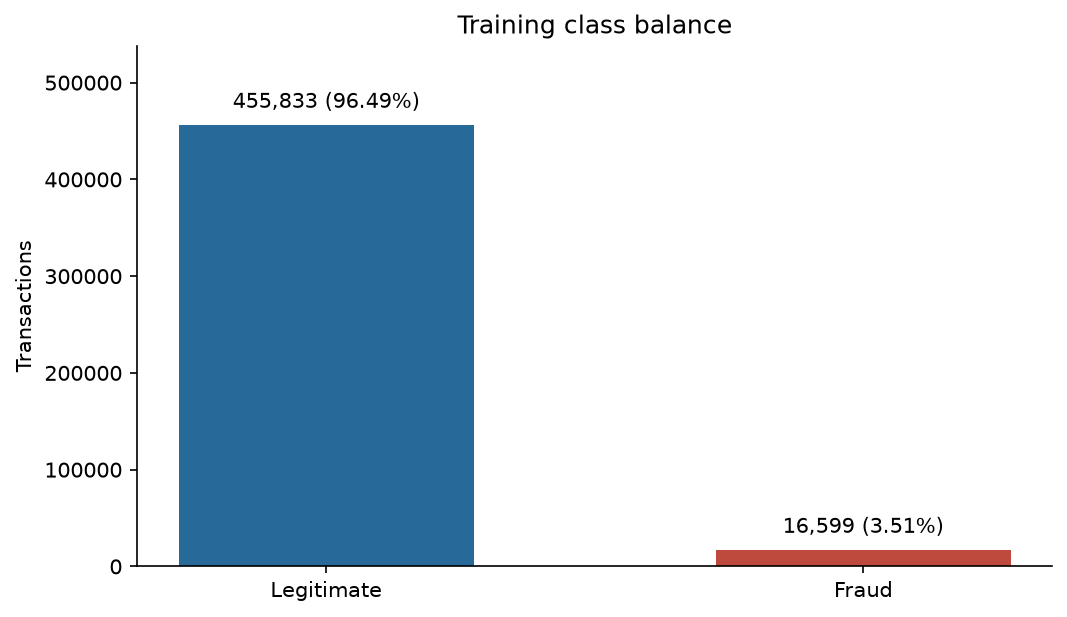

,group,rows,fraud,fraud_rate,share
0,0,455833,0,0.0,0.964865
1,1,16599,16599,1.0,0.035135


In [2]:
balance = tables["class_balance"].set_index("group").loc[["0", "1"]]
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
bars = ax.bar(["Legitimate", "Fraud"], balance.rows, color=[BLUE, RED], width=.55)
ax.bar_label(bars, labels=[f"{n:,} ({100*n/len(train):.2f}%)" for n in balance.rows], padding=6)
ax.set_ylim(0, balance.rows.max() * 1.18)
ax.set_ylabel("Transactions")
ax.set_title("Training class balance")
save(fig, "class_balance")
display(tables["class_balance"])

## Amount distributions and observed fraud rates

Each class histogram sums to 100%, so the chart compares shapes rather than class sizes. The horizontal amount scale is logarithmic. Fixed bands on the right show unadjusted fraud rates and their transaction counts. Currency is not established; amounts are dataset units.

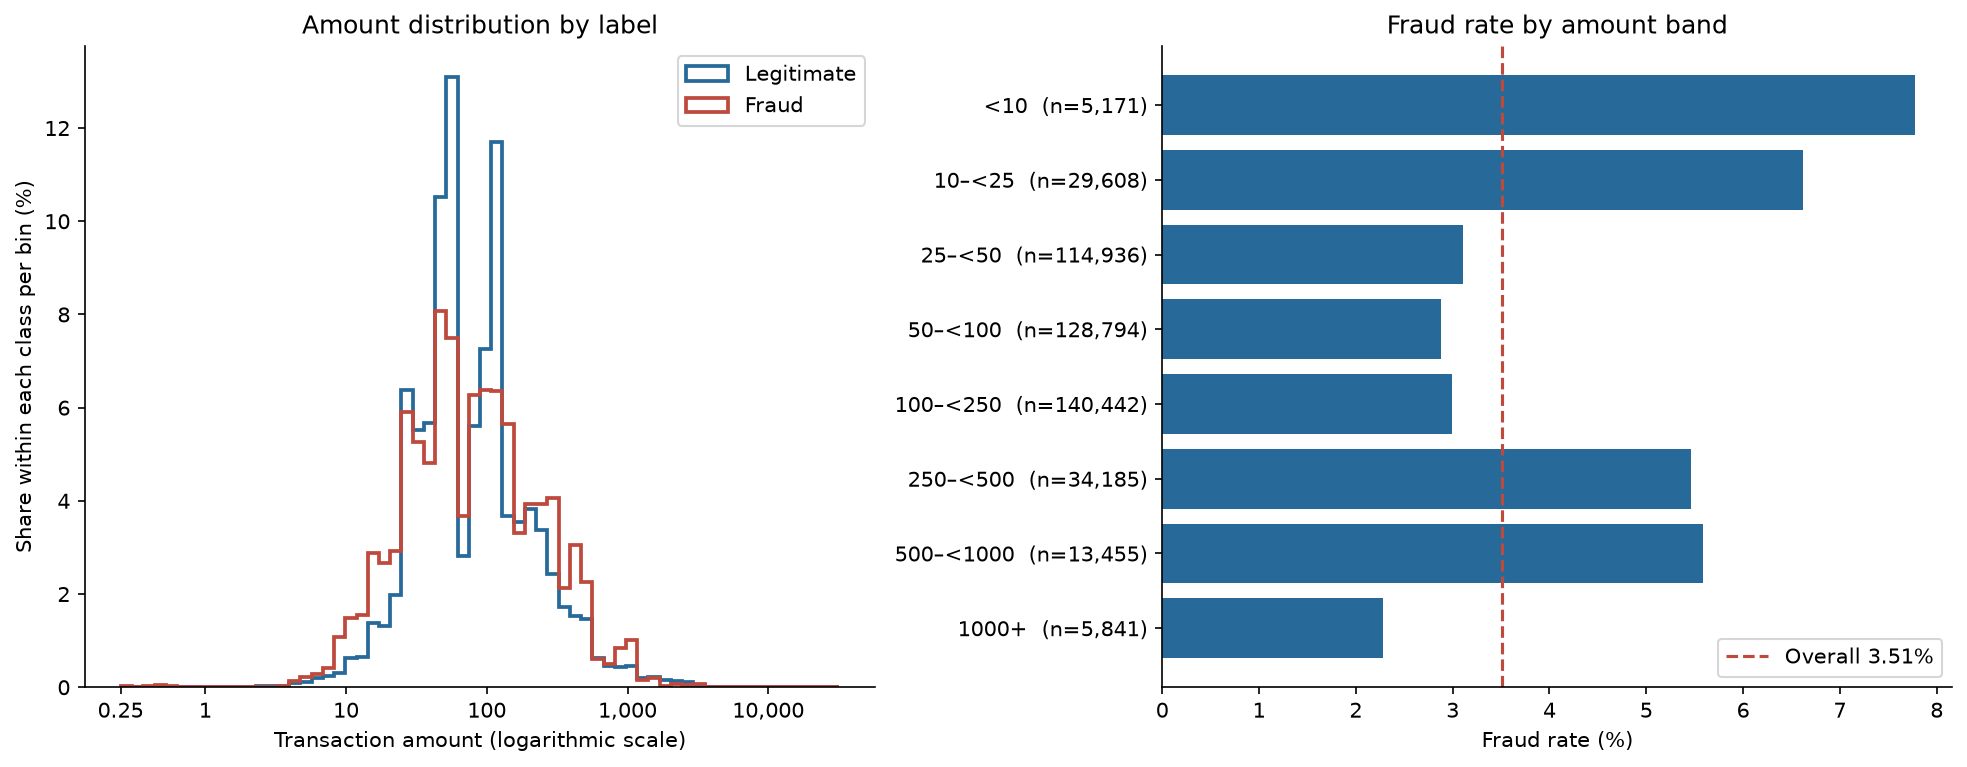

,isFraud,rows,mean,median,p95,p99,max
0,0,455833,133.87,68.50,433.0,1104.0,31937.39
1,1,16599,149.04,76.13,500.0,994.0,5191.00


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
log_amount = np.log10(train.TransactionAmt.to_numpy())
bins = np.linspace(log_amount.min(), log_amount.max(), 65)
for label, color, name in [(0, BLUE, "Legitimate"), (1, RED, "Fraud")]:
    values = log_amount[train.isFraud.to_numpy() == label]
    axes[0].hist(values, bins=bins, weights=np.full(len(values), 100/len(values)),
                 histtype="step", linewidth=1.8, color=color, label=name)
ticks = np.array([.25, 1, 10, 100, 1000, 10000])
axes[0].set_xticks(np.log10(ticks), ["0.25", "1", "10", "100", "1,000", "10,000"])
axes[0].set_xlabel("Transaction amount (logarithmic scale)")
axes[0].set_ylabel("Share within each class per bin (%)")
axes[0].set_title("Amount distribution by label")
axes[0].legend()
bands = tables["amount_bins"]
labels = [f"{r.group}  (n={r.rows:,})" for r in bands.itertuples()]
axes[1].barh(labels, 100*bands.fraud_rate, color=BLUE)
axes[1].axvline(baseline, color=RED, linestyle="--", label=f"Overall {baseline:.2f}%")
axes[1].set_xlabel("Fraud rate (%)")
axes[1].set_title("Fraud rate by amount band")
axes[1].invert_yaxis()
axes[1].legend(loc="lower right")
save(fig, "amounts")
display(tables["amount_summary"].round(2))

## Missingness

The first figure shows the twenty most incomplete columns. The next compares fraud rates when values are missing versus present, selecting the ten largest absolute gaps among columns with at least 1% of rows on each side. Related features can share the same missingness pattern, so these are not independent signals.

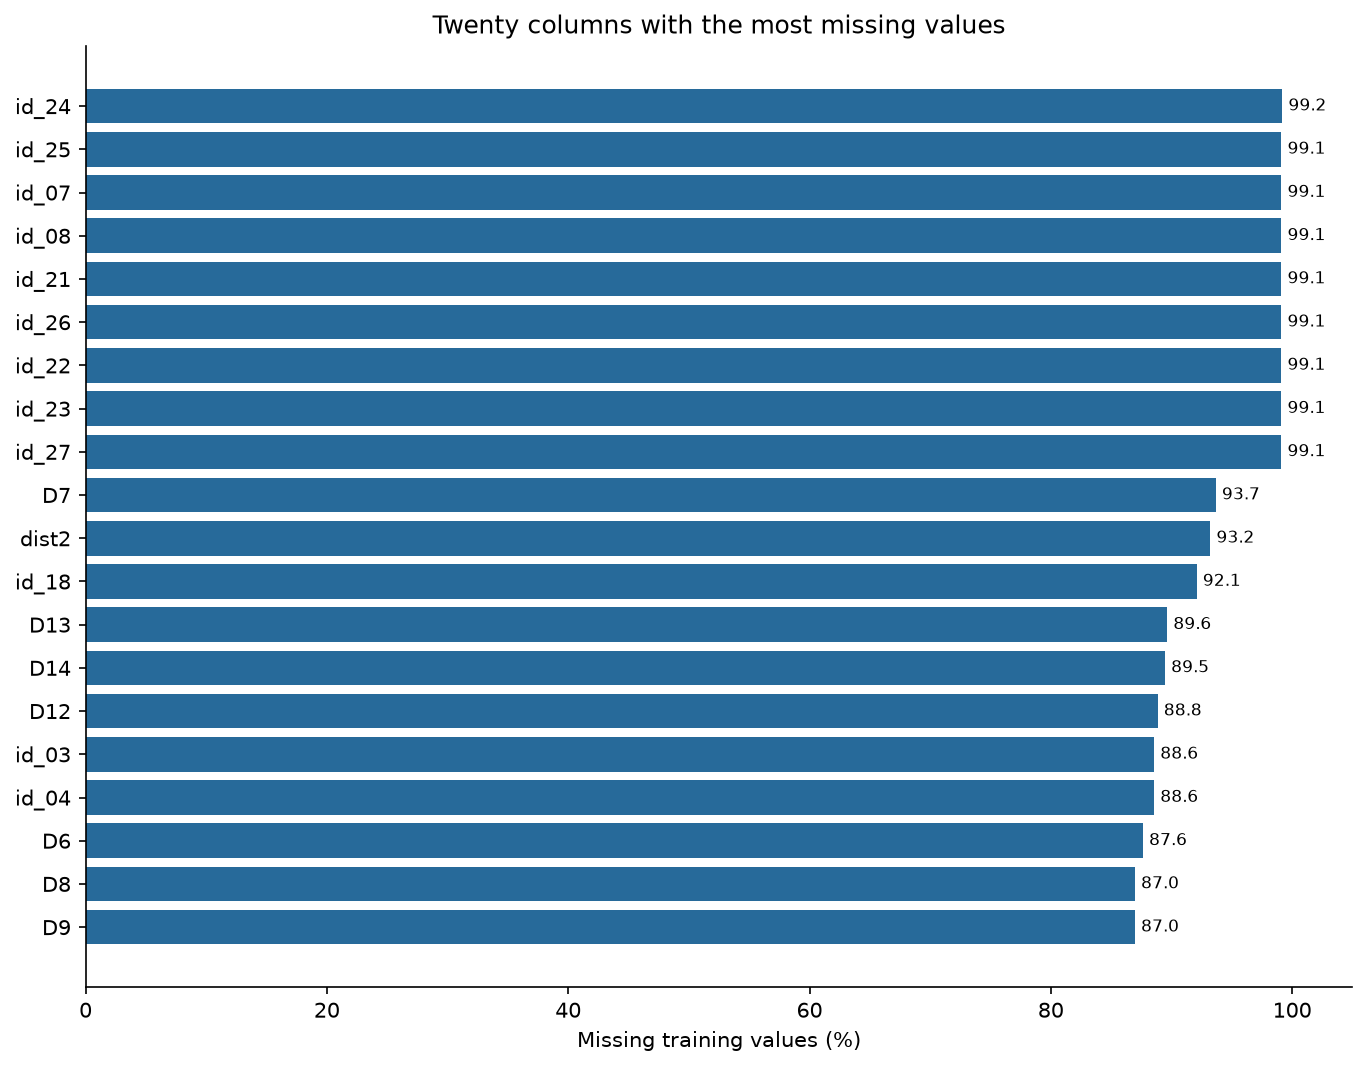

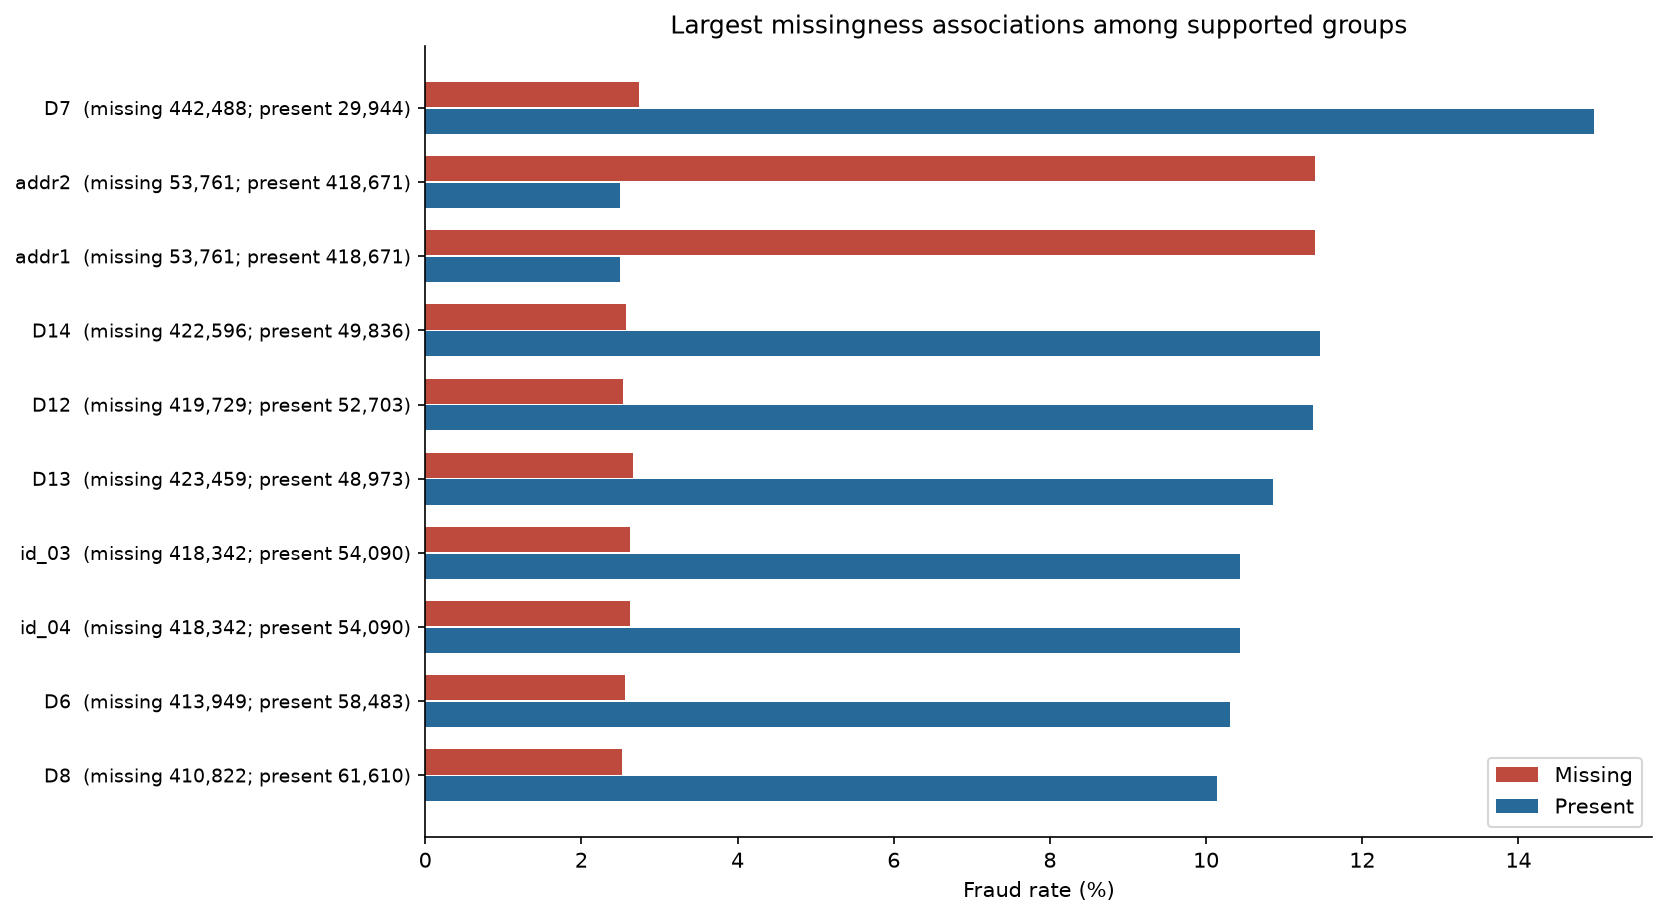

In [4]:
profile = tables["missingness"]
top = profile.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7), layout="constrained")
ax.barh(top.column, top.pct_missing, color=BLUE)
ax.set_xlim(0, 105)
ax.set_xlabel("Missing training values (%)")
ax.set_title("Twenty columns with the most missing values")
ax.bar_label(ax.containers[0], fmt="%.1f", padding=3, fontsize=8)
save(fig, "missingness")

selected = profile.loc[profile.pct_missing.between(1, 99)].copy()
selected = selected.loc[selected.rate_gap_pp.abs().sort_values(ascending=False).head(10).index]
fig, ax = plt.subplots(figsize=(11, 6), layout="constrained")
y = np.arange(len(selected))
ax.barh(y-.18, 100*selected.fraud_rate_missing, height=.34, label="Missing", color=RED)
ax.barh(y+.18, 100*selected.fraud_rate_present, height=.34, label="Present", color=BLUE)
labels = [f"{r.column}  (missing {r.missing_rows:,}; present {r.present_rows:,})" for r in selected.itertuples()]
ax.set_yticks(y, labels, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Fraud rate (%)")
ax.set_title("Largest missingness associations among supported groups")
ax.legend(loc="lower right")
save(fig, "missingness_rates")

## Product, card, and device categories

Bars show observed fraud rates. Each label includes its group size; `<missing>` is retained as its own group. The dashed line is the overall training rate. These are associations, not effects adjusted for time or other features.

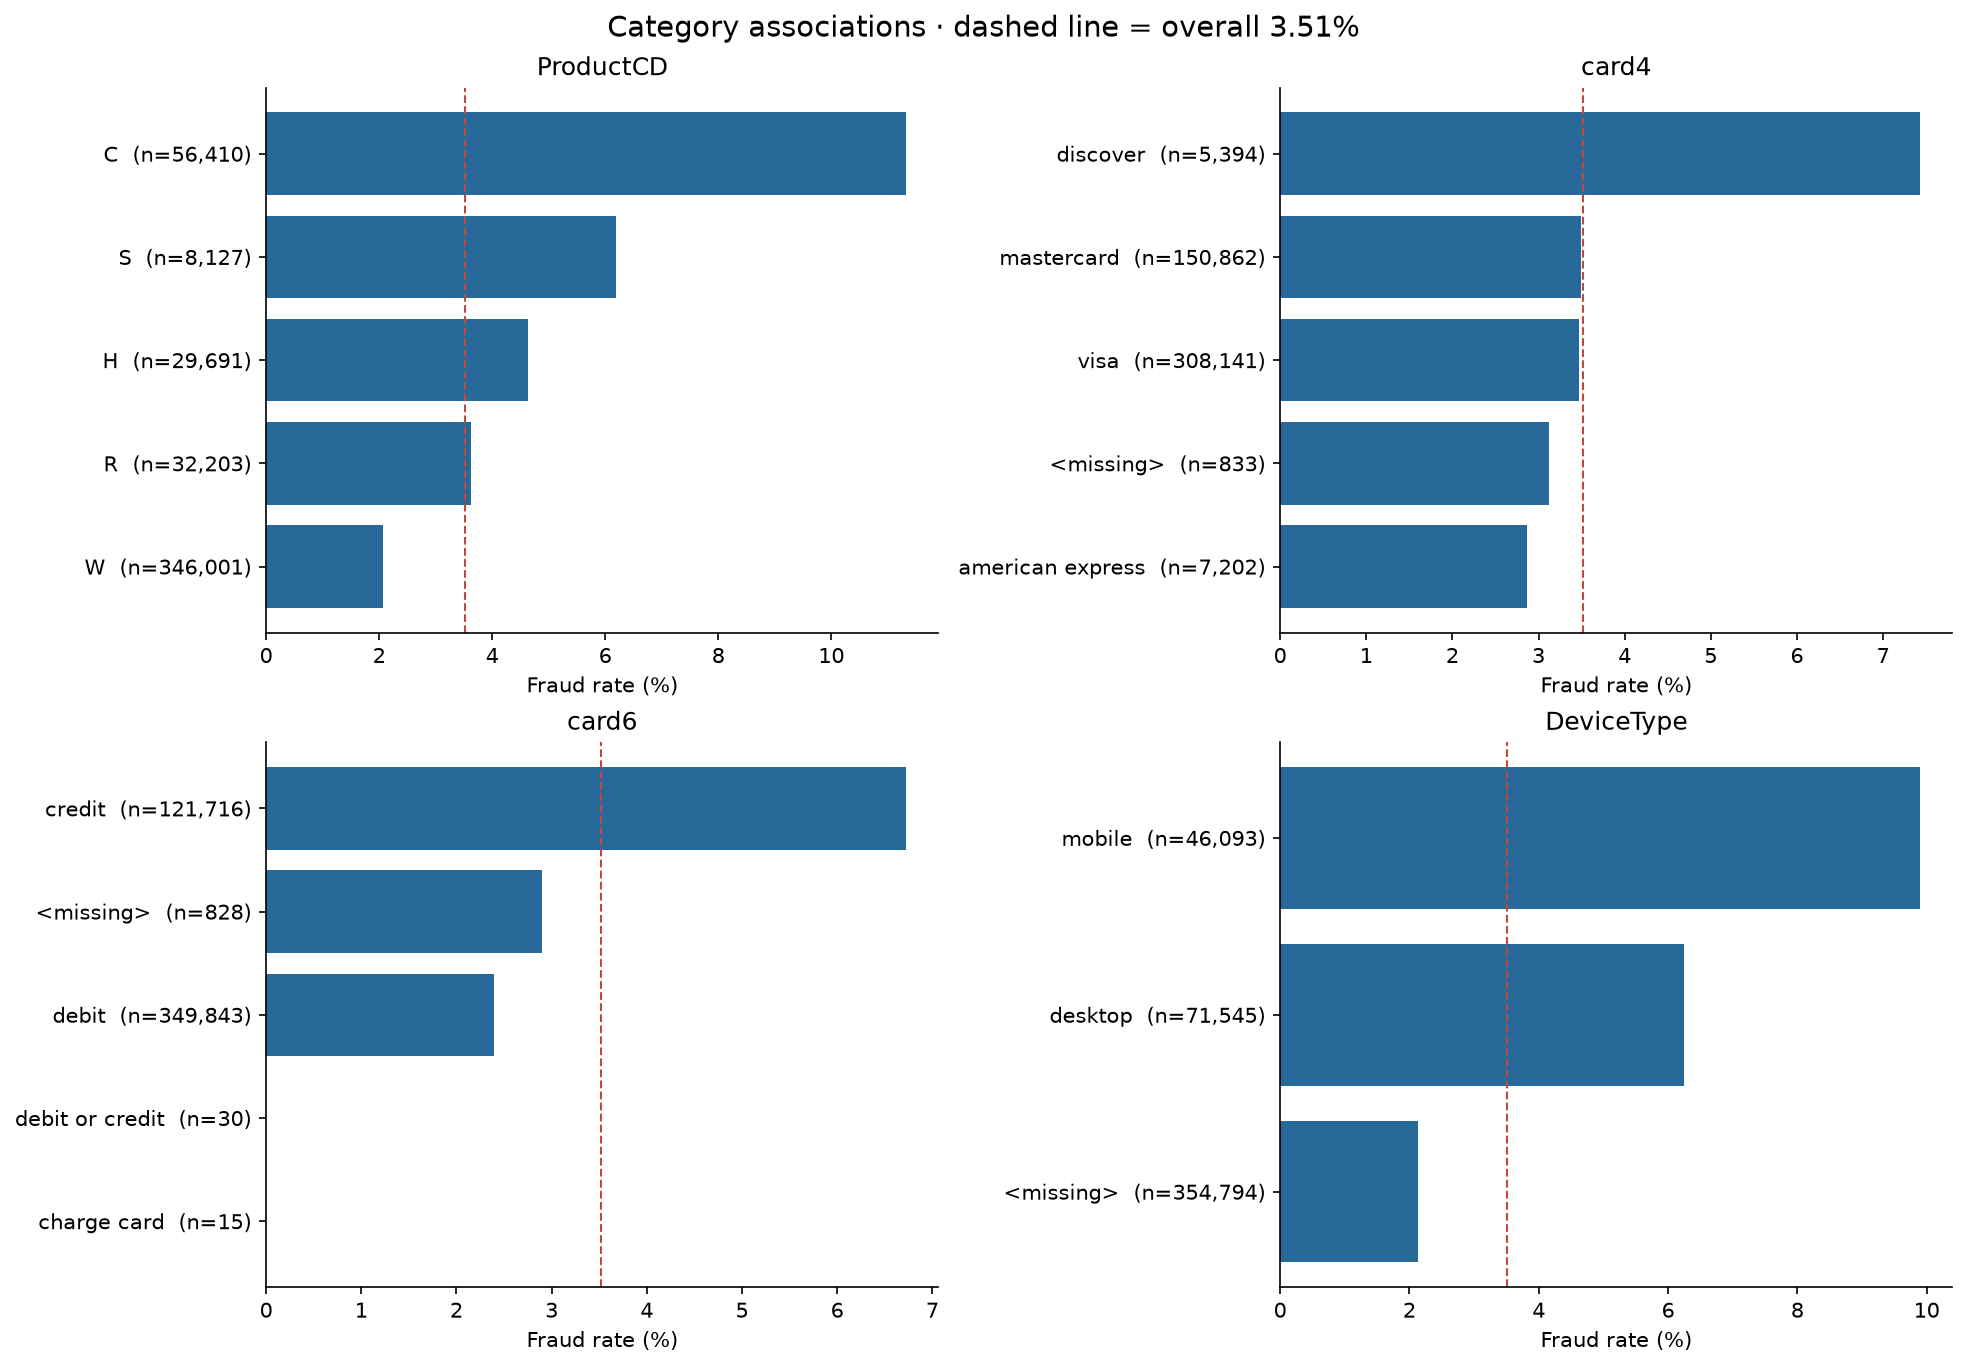

,group,rows,fraud,fraud_rate,share
0,0,351968,7500,0.021309,0.745013
1,1,120464,9099,0.075533,0.254987


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), layout="constrained")
for ax, column in zip(axes.flat, ["ProductCD", "card4", "card6", "DeviceType"]):
    group = tables["category_" + column].sort_values("fraud_rate", ascending=False)
    labels = [f"{r.group}  (n={r.rows:,})" for r in group.itertuples()]
    ax.barh(labels, 100*group.fraud_rate, color=BLUE)
    ax.axvline(baseline, color=RED, linestyle="--", linewidth=1)
    ax.invert_yaxis()
    ax.set_xlabel("Fraud rate (%)")
    ax.set_title(column)
fig.suptitle(f"Category associations · dashed line = overall {baseline:.2f}%", fontsize=14)
save(fig, "categories")
display(tables["category_has_identity"])

## Email domains

For each email column, show the eight largest nonmissing groups by transaction count, the missing group, and all remaining domains pooled. Pooling is only for this chart; full tables retain every domain. Domain rates do not imply wrongdoing by providers.

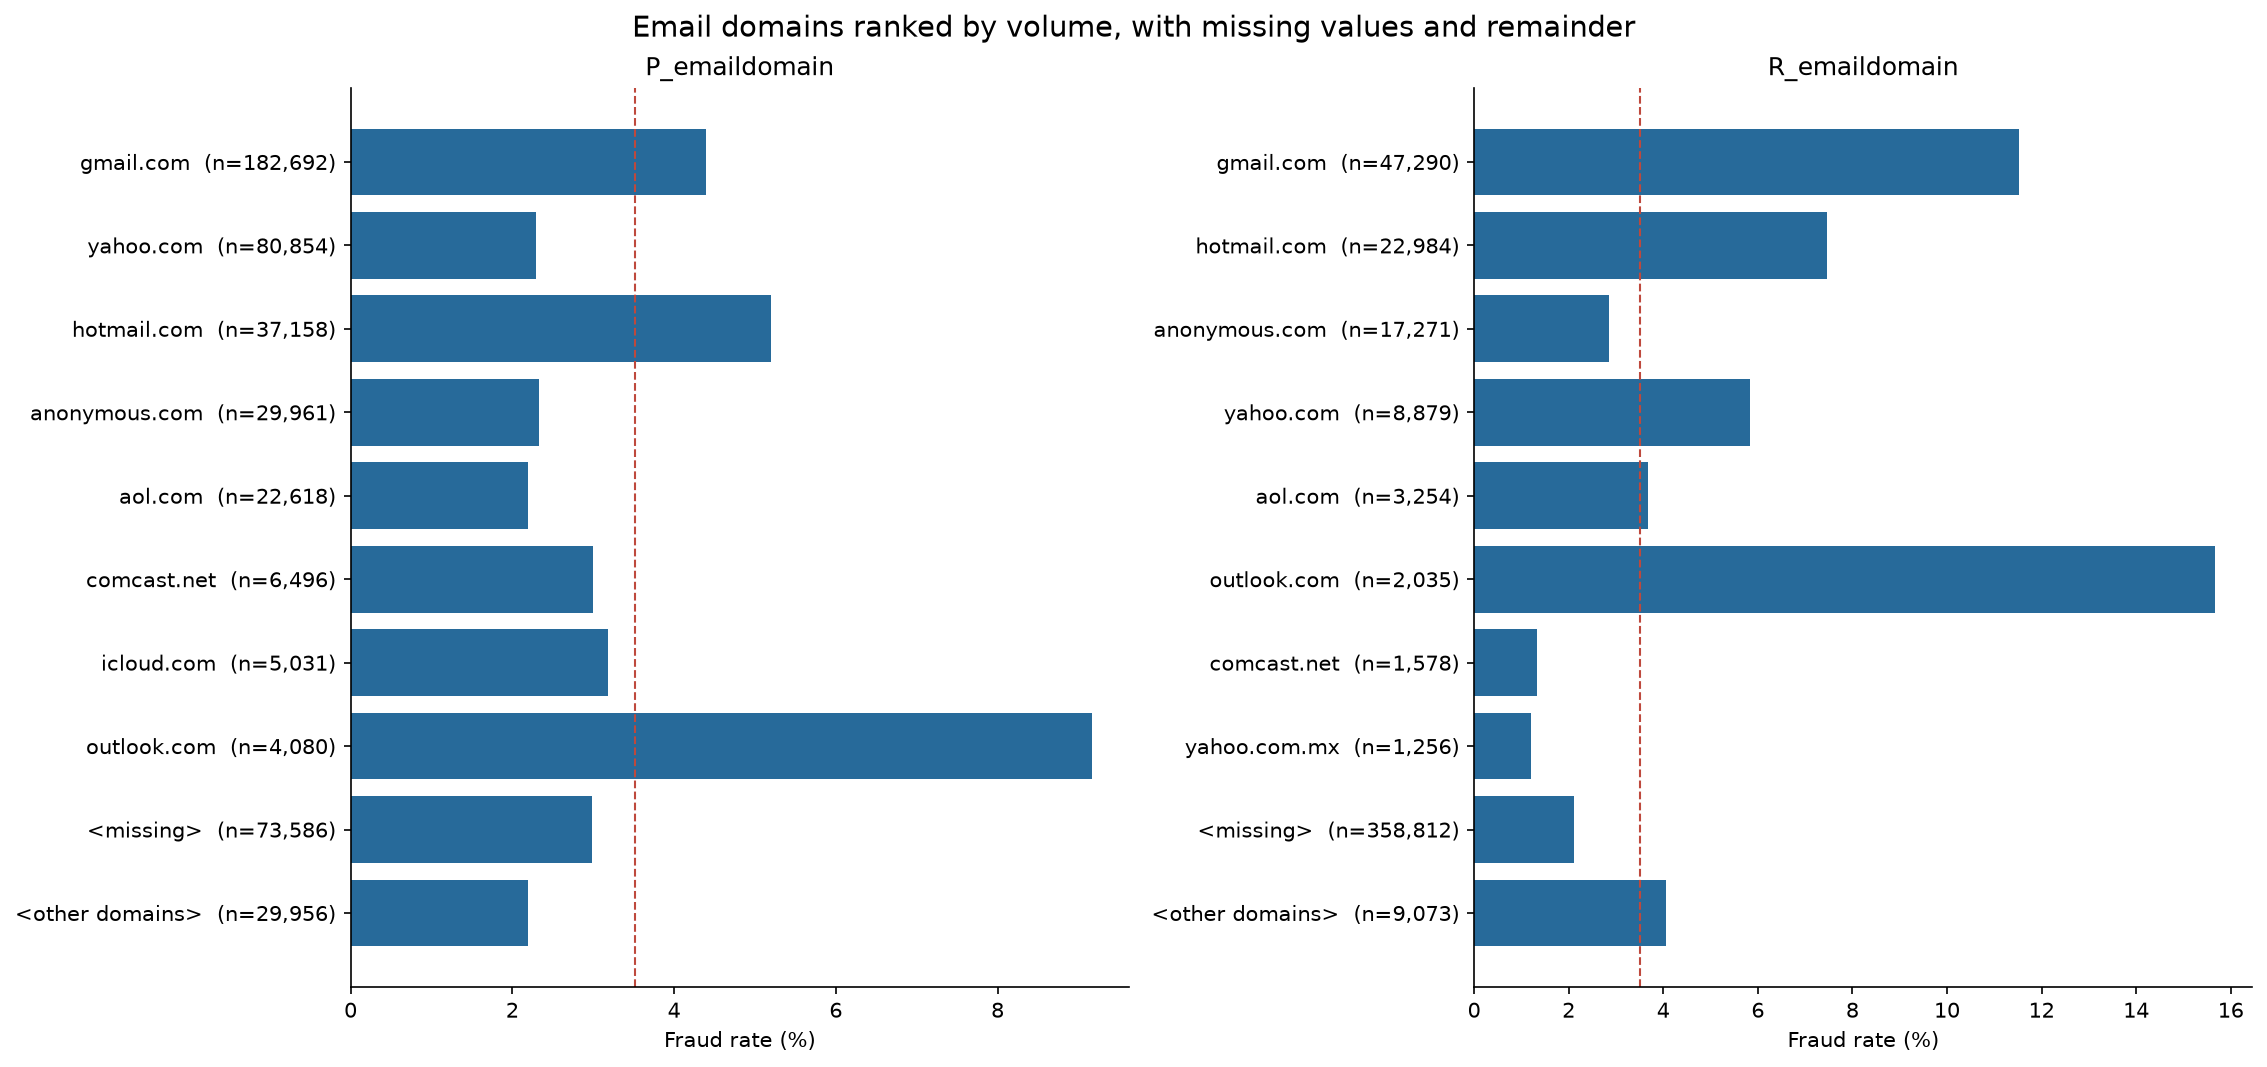

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7), layout="constrained")
for ax, column in zip(axes, ["P_emaildomain", "R_emaildomain"]):
    full = tables["category_" + column]
    common = full.loc[full.group != "<missing>"].nlargest(8, "rows")
    missing = full.loc[full.group == "<missing>"]
    rest = full.loc[~full.group.isin(pd.concat([common, missing]).group)]
    shown = pd.concat([common, missing], ignore_index=True)
    if len(rest):
        other = pd.DataFrame([{"group": "<other domains>", "rows": int(rest.rows.sum()),
                               "fraud": int(rest.fraud.sum()),
                               "fraud_rate": rest.fraud.sum()/rest.rows.sum()}])
        shown = pd.concat([shown, other], ignore_index=True)
    assert shown.rows.sum() == len(train)
    assert shown.fraud.sum() == train.isFraud.sum()
    labels = [f"{r.group}  (n={r.rows:,})" for r in shown.itertuples()]
    ax.barh(labels, 100*shown.fraud_rate, color=BLUE)
    ax.axvline(baseline, color=RED, linestyle="--", linewidth=1)
    ax.invert_yaxis()
    ax.set_xlabel("Fraud rate (%)")
    ax.set_title(column)
fig.suptitle("Email domains ranked by volume, with missing values and remainder", fontsize=14)
save(fig, "email_domains")

## Changes over relative time

Intervals are seven days long, starting at the first training day. Gray shading marks an interval without a full seven-day observed span; its volume should not be compared directly with complete weeks. Relative days do not identify calendar dates or weekdays. Variation can reflect transaction mix and is not by itself evidence of concept drift.

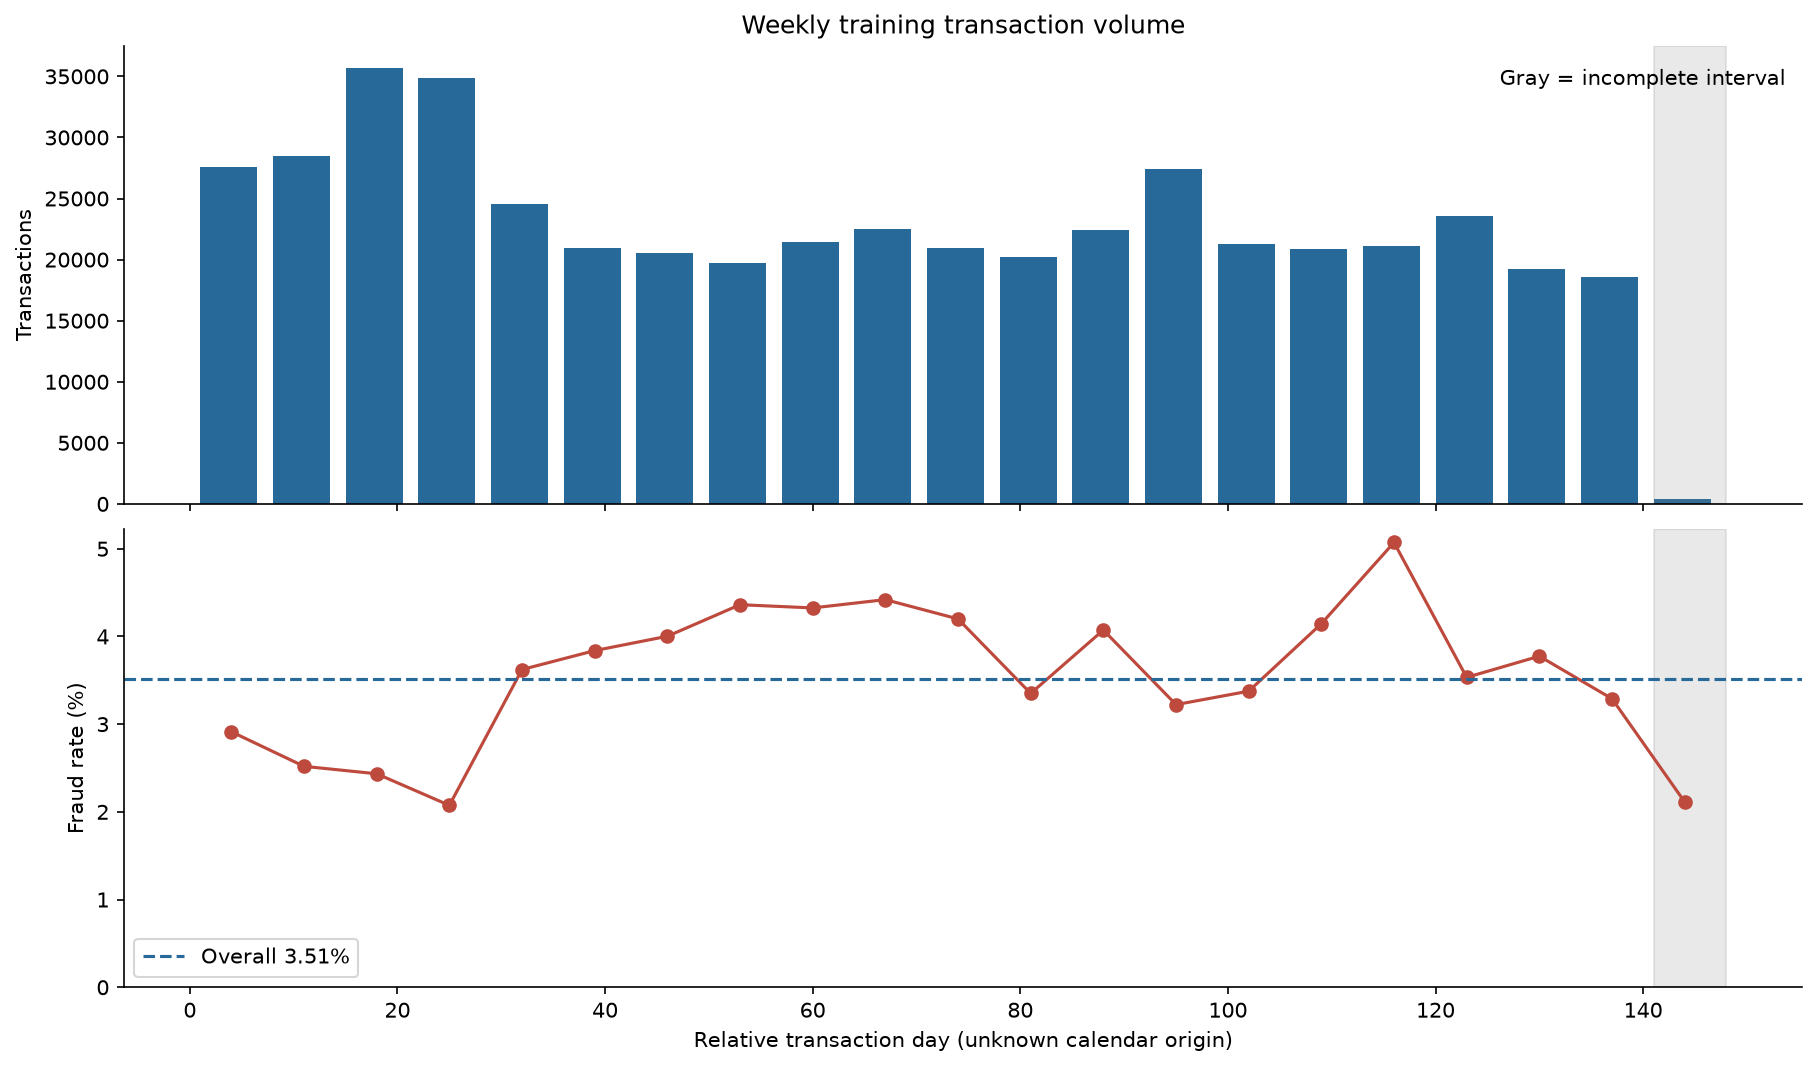

,start_day,end_day,rows,fraud,fraud_rate,complete_interval
0,1,7,27596,804,0.029135,True
1,8,14,28463,717,0.025191,True
2,15,21,35701,869,0.024341,True
3,22,28,34906,724,0.020741,True
4,29,35,24539,889,0.036228,True
5,36,42,20919,803,0.038386,True
6,43,49,20564,823,0.040021,True
7,50,56,19761,862,0.043621,True
8,57,63,21432,927,0.043253,True
9,64,70,22534,996,0.044200,True


In [7]:
weekly = tables["weekly"]
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, layout="constrained")
x = weekly.start_day.to_numpy()
axes[0].bar(x, weekly.rows, width=5.5, align="edge", color=BLUE)
axes[0].set_ylabel("Transactions")
axes[0].set_title("Weekly training transaction volume")
axes[1].plot(x+3, 100*weekly.fraud_rate, marker="o", color=RED)
axes[1].axhline(baseline, color=BLUE, linestyle="--", label=f"Overall {baseline:.2f}%")
axes[1].set_ylabel("Fraud rate (%)")
axes[1].set_xlabel("Relative transaction day (unknown calendar origin)")
axes[1].set_ylim(bottom=0)
axes[1].legend(loc="lower left")
for ax in axes:
    for row in weekly.loc[~weekly.complete_interval].itertuples():
        ax.axvspan(row.start_day, row.end_day+1, color="gray", alpha=.17)
axes[0].text(.99, .95, "Gray = incomplete interval", transform=axes[0].transAxes, ha="right", va="top")
save(fig, "time")
display(weekly[["start_day", "end_day", "rows", "fraud", "fraud_rate", "complete_interval"]])

## Findings and limits

Read `reports/eda_findings.md` for the generated findings with source tables. All category and weekly counts reconcile to the same training population. No model has been fitted and no preprocessing decision is automatically applied by this notebook. Customer dependence, product mix, and small category counts limit interpretation of unadjusted fraud rates.